# EDA de felicidad mundial: diferencias, asociaciones y cambios

![La llave de la felicidad: un viaje por los datos](../reports/figures/banner_presentacion.png)

## Objetivo

Analizo cómo varía la puntuación de felicidad entre países y qué aportes del modelo del World Happiness Report están más relacionados con ella. Desarrollo este proyecto de forma individual.

Busco responder tres preguntas:
1. ¿Cómo se distribuyen las puntuaciones y qué países presentan los valores extremos?
2. ¿Qué aportes del modelo muestran mayor asociación con la felicidad?
3. ¿Cómo cambian las puntuaciones al comparar los mismos países entre dos cortes?

## Datos y alcance

Utilizo el archivo WHR26_Data_Figure_2.1.xlsx del World Happiness Report 2026. Contiene 2.116 registros y 13 columnas originales, con etiquetas temporales entre 2011 y 2025, sin 2013.

El análisis principal corresponde al periodo 2023–2025, etiquetado como 2025 en el archivo:
- 147 países para analizar las puntuaciones de felicidad.
- 145 países con los seis factores completos para calcular correlaciones.
- 144 países comunes para comparar los cortes 2019 y 2025.

La puntuación de felicidad es una evaluación de vida en una escala de 0 a 10. Los seis factores disponibles son aportes del modelo explicativo, no indicadores brutos.

## Método de trabajo

Inspecciono los datos, documento nulos y duplicados, traduzco columnas y países, reviso valores atípicos y exporto los datos preparados a CSV. Después calculo estadísticas descriptivas, elaboro gráficos y analizo correlaciones y cambios temporales.

Conservo una copia original y no imputo valores ausentes. Las medias entre países no están ponderadas por población.

Incluyo una selección personal de países y el caso complementario de Bután. Distingo los resultados descriptivos de las explicaciones causales y documento las limitaciones de cobertura y comparabilidad.

In [24]:
# Cargo las herramientas que utilizo en el análisis.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import openpyxl

print("Python utilizado:", sys.executable)
print("Herramientas cargadas correctamente.")

Python utilizado: c:\Users\PC\Documents\Proyecto 6\.venv\Scripts\python.exe
Herramientas cargadas correctamente.


In [25]:
%pip install numpy pandas matplotlib openpyxl requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from pathlib import Path
import hashlib
import pandas as pd
import requests

# Localizo la carpeta principal del proyecto.
carpeta_proyecto = Path.cwd().resolve()

if carpeta_proyecto.name == "notebooks":
    carpeta_proyecto = carpeta_proyecto.parent

ruta_excel = (
    carpeta_proyecto / "data" / "raw" / "WHR26_Data_Figure_2.1.xlsx"
)

url_datos = "https://files.worldhappiness.report/WHR26_Data_Figure_2.1.xlsx"
hash_esperado = "576e382655cec3ae704a0b41cd2c04465b87cd84b7f131a0c4fa26d41f6d8028"

# Descargo el archivo solo cuando no está disponible en el equipo.
if not ruta_excel.is_file():
    respuesta = requests.get(url_datos, timeout=60)
    respuesta.raise_for_status()

    # Verifico que corresponde a la versión utilizada en mi análisis.
    hash_descarga = hashlib.sha256(respuesta.content).hexdigest()
    if hash_descarga != hash_esperado:
        raise ValueError(
            "La descarga difiere de la versión analizada. "
            "Reviso la fuente antes de guardar el archivo."
        )

    ruta_excel.parent.mkdir(parents=True, exist_ok=True)
    ruta_excel.write_bytes(respuesta.content)
    print("Excel descargado:", ruta_excel)
else:
    print("Utilizo el Excel local:", ruta_excel)

# Compruebo también la integridad del archivo local.
hash_local = hashlib.sha256(ruta_excel.read_bytes()).hexdigest()
if hash_local != hash_esperado:
    raise ValueError("El Excel local no coincide con la versión verificada.")

print("Integridad del Excel verificada.")

excel = pd.ExcelFile(ruta_excel)
print("Hojas disponibles:", excel.sheet_names)

Utilizo el Excel local: C:\Users\PC\Documents\Proyecto 6\data\raw\WHR26_Data_Figure_2.1.xlsx
Integridad del Excel verificada.
Hojas disponibles: ['Data for Figure 2.1 (2011–2025)']


In [27]:
# Revisamos las primeras filas para localizar los encabezados.
vista_previa = pd.read_excel(ruta_excel, sheet_name=0, header=None)
display(vista_previa.head(12))

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Year,Rank,Country name,Life evaluation (3-year average),Lower whisker,Upper whisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
1,2025,1,Finland,7.764,7.69,7.837,1.915,1.638,0.939,1.105,0.093,0.491,1.582
2,2025,2,Iceland,7.54,7.449,7.63,1.971,1.72,0.996,1.105,0.187,0.187,1.373
3,2025,3,Denmark,7.539,7.446,7.631,1.986,1.633,0.93,1.081,0.125,0.474,1.31
4,2025,4,Costa Rica,7.439,7.356,7.522,1.697,1.483,0.739,1.101,0.059,0.122,2.236
5,2025,5,Sweden,7.255,7.172,7.337,1.95,1.57,1.027,1.07,0.149,0.447,1.041
6,2025,6,Norway,7.242,7.156,7.327,2.057,1.626,0.983,1.092,0.157,0.413,0.913
7,2025,7,Netherlands,7.223,7.153,7.293,1.983,1.539,0.922,1,0.175,0.349,1.255
8,2025,8,Israel,7.187,7.119,7.254,1.867,1.606,0.925,0.863,0.139,0.196,1.592
9,2025,9,Luxembourg,7.063,6.971,7.154,2.162,1.465,0.981,1.056,0.111,0.382,0.907


In [28]:
# Cargamos los datos y conservamos una copia original sin modificar.
df_original = pd.read_excel(ruta_excel, sheet_name=0, header=0)
df = df_original.copy()

print("Filas y columnas:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nAños disponibles:")
print(sorted(df["Year"].dropna().unique().tolist()))

Filas y columnas: (2116, 13)

Columnas:
['Year', 'Rank', 'Country name', 'Life evaluation (3-year average)', 'Lower whisker', 'Upper whisker', 'Explained by: Log GDP per capita', 'Explained by: Social support', 'Explained by: Healthy life expectancy', 'Explained by: Freedom to make life choices', 'Explained by: Generosity', 'Explained by: Perceptions of corruption', 'Dystopia + residual']

Años disponibles:
[2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [29]:
# Diagnóstico inicial: todavía no modificamos los datos.
resumen_inicial = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2)
})

display(resumen_inicial)

print("Filas duplicadas completas:", df.duplicated().sum())
print(
    "Registros repetidos por país y año:",
    df.duplicated(subset=["Country name", "Year"]).sum()
)

,tipo,nulos,porcentaje_nulos
Year,int64,0,0.00
Rank,int64,0,0.00
Country name,str,0,0.00
Life evaluation (3-year average),float64,0,0.00
Lower whisker,float64,1094,51.70
Upper whisker,float64,1094,51.70
Explained by: Log GDP per capita,float64,1097,51.84
Explained by: Social support,float64,1097,51.84
Explained by: Healthy life expectancy,float64,1100,51.98
Explained by: Freedom to make life choices,float64,1099,51.94


Filas duplicadas completas: 0
Registros repetidos por país y año: 0


In [30]:
# Compruebo en qué años faltan datos para decidir cómo tratarlos.
columnas_factores = [
    columna for columna in df.columns
    if columna.startswith("Explained by:")
]

resumen_por_anio = df.groupby("Year").agg(
    registros=("Country name", "size"),
    paises=("Country name", "nunique")
)

# Calculo el porcentaje de valores vacíos de cada factor por año.
nulos_por_anio = (
    df.groupby("Year")[columnas_factores]
    .agg(lambda columna: columna.isna().mean() * 100)
    .round(2)
)

display(resumen_por_anio)
display(nulos_por_anio)

,registros,paises
Year,,
2011,156,156
2012,156,156
2014,158,158
2015,157,157
2016,155,155
2017,156,156
2018,156,156
2019,153,153
2020,149,149


,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption
Year,,,,,,
2011,100.0,100.0,100.00,100.00,100.0,100.00
2012,100.0,100.0,100.00,100.00,100.0,100.00
2014,100.0,100.0,100.00,100.00,100.0,100.00
2015,100.0,100.0,100.00,100.00,100.0,100.00
2016,100.0,100.0,100.00,100.00,100.0,100.00
2017,100.0,100.0,100.00,100.00,100.0,100.00
2018,100.0,100.0,100.00,100.00,100.0,100.00
2019,0.0,0.0,0.00,0.00,0.0,0.00
2020,0.0,0.0,0.00,0.00,0.0,0.00


In [31]:
# Selecciono el último año disponible para el análisis principal.
anio_actual = df["Year"].max()
df_actual = df.loc[df["Year"] == anio_actual].copy()

# Localizo los países que tienen algún factor sin datos.
faltan_factores = df_actual[columnas_factores].isna().any(axis=1)

print("Año seleccionado:", anio_actual)
print("Países:", len(df_actual))
print("Países con algún factor vacío:", faltan_factores.sum())

# Muestro solo los países afectados y sus factores.
display(
    df_actual.loc[
        faltan_factores,
        ["Country name"] + columnas_factores
    ].T
)

Año seleccionado: 2025
Países: 147
Países con algún factor vacío: 2


,87,108
Country name,Tajikistan,State of Palestine
Explained by: Log GDP per capita,1.18,1.242
Explained by: Social support,1.476,1.335
Explained by: Healthy life expectancy,0.783,NaN
Explained by: Freedom to make life choices,NaN,0.742
Explained by: Generosity,0.085,0.073
Explained by: Perceptions of corruption,0.336,0.095


In [32]:
# Conservo los 147 países en df_actual, aunque falte algún factor.
# Creo otra tabla con los seis factores completos para compararlos juntos.
df_factores = df_actual.dropna(subset=columnas_factores).copy()

# Dejo registradas las cifras para explicar mi decisión en el informe.
total = len(df_actual)
excluidos = total - len(df_factores)

print("Países para analizar la felicidad:", total)
print("Países con los seis factores completos:", len(df_factores))
print(
    f"Países excluidos solo del análisis conjunto de factores: "
    f"{excluidos} ({excluidos / total:.2%})"
)
print("Valores rellenados artificialmente: 0")

Países para analizar la felicidad: 147
Países con los seis factores completos: 145
Países excluidos solo del análisis conjunto de factores: 2 (1.36%)
Valores rellenados artificialmente: 0


In [33]:
# Traduzco las columnas para trabajar y presentar los resultados en español.
traduccion_columnas = {
    "Year": "anio",
    "Rank": "posicion",
    "Country name": "pais",
    "Life evaluation (3-year average)": "felicidad_media_3_anios",
    "Lower whisker": "limite_inferior",
    "Upper whisker": "limite_superior",
    "Explained by: Log GDP per capita": "aporte_pib",
    "Explained by: Social support": "aporte_apoyo_social",
    "Explained by: Healthy life expectancy": "aporte_vida_saludable",
    "Explained by: Freedom to make life choices": "aporte_libertad",
    "Explained by: Generosity": "aporte_generosidad",
    "Explained by: Perceptions of corruption": "aporte_corrupcion",
    "Dystopia + residual": "distopia_mas_residuo"
}

# Aplico los mismos nombres a las tres tablas que estoy utilizando.
df = df.rename(columns=traduccion_columnas)
df_actual = df_actual.rename(columns=traduccion_columnas)
df_factores = df_factores.rename(columns=traduccion_columnas)

# Actualizo la lista de factores para usar sus nombres en español.
columnas_factores = [
    nombre for nombre in traduccion_columnas.values()
    if nombre.startswith("aporte_")
]

print("Columnas en español:")
for columna in df.columns:
    print(columna)

Columnas en español:
anio
posicion
pais
felicidad_media_3_anios
limite_inferior
limite_superior
aporte_pib
aporte_apoyo_social
aporte_vida_saludable
aporte_libertad
aporte_generosidad
aporte_corrupcion
distopia_mas_residuo


In [34]:
# Conservo el nombre original de cada país para poder comprobarlo después.
for tabla in [df, df_actual, df_factores]:
    tabla["pais_original"] = tabla["pais"].copy()

# Consulto los nombres de todos los años para preparar una traducción completa.
paises_originales = sorted(df["pais_original"].dropna().unique())

print("Nombres de países y territorios distintos:", len(paises_originales))
print("\n".join(paises_originales))

Nombres de países y territorios distintos: 168
Afghanistan
Albania
Algeria
Angola
Argentina
Armenia
Australia
Austria
Azerbaijan
Bahrain
Bangladesh
Belarus
Belgium
Belize
Benin
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
Bulgaria
Burkina Faso
Burundi
Cambodia
Cameroon
Canada
Central African Republic
Chad
Chile
China
Colombia
Comoros
Congo
Costa Rica
Croatia
Cuba
Cyprus
Czechia
Côte d’Ivoire
DR Congo
Denmark
Djibouti
Dominican Republic
Ecuador
Egypt
El Salvador
Estonia
Eswatini
Ethiopia
Finland
France
Gabon
Gambia
Georgia
Germany
Ghana
Greece
Guatemala
Guinea
Guyana
Haiti
Honduras
Hong Kong SAR of China
Hungary
Iceland
India
Indonesia
Iran
Iraq
Ireland
Israel
Italy
Jamaica
Japan
Jordan
Kazakhstan
Kenya
Kosovo
Kuwait
Kyrgyzstan
Lao PDR
Latvia
Lebanon
Lesotho
Liberia
Libya
Lithuania
Luxembourg
Madagascar
Malawi
Malaysia
Maldives
Mali
Malta
Mauritania
Mauritius
Mexico
Mongolia
Montenegro
Morocco
Mozambique
Myanmar
Namibia
Nepal
Netherlands
New Zealand
Nicaragua
Niger
Nigeria
Nort

In [35]:
# Traduzco los países y unifico Suazilandia y Esuatini desde el principio.
traduccion_paises = {
    "Afghanistan": "Afganistán",
    "Albania": "Albania",
    "Algeria": "Argelia",
    "Angola": "Angola",
    "Argentina": "Argentina",
    "Armenia": "Armenia",
    "Australia": "Australia",
    "Austria": "Austria",
    "Azerbaijan": "Azerbaiyán",
    "Bahrain": "Baréin",
    "Bangladesh": "Bangladés",
    "Belarus": "Bielorrusia",
    "Belgium": "Bélgica",
    "Belize": "Belice",
    "Benin": "Benín",
    "Bhutan": "Bután",
    "Bolivia": "Bolivia",
    "Bosnia and Herzegovina": "Bosnia y Herzegovina",
    "Botswana": "Botsuana",
    "Brazil": "Brasil",
    "Bulgaria": "Bulgaria",
    "Burkina Faso": "Burkina Faso",
    "Burundi": "Burundi",
    "Cambodia": "Camboya",
    "Cameroon": "Camerún",
    "Canada": "Canadá",
    "Central African Republic": "República Centroafricana",
    "Chad": "Chad",
    "Chile": "Chile",
    "China": "China",
    "Colombia": "Colombia",
    "Comoros": "Comoras",
    "Congo": "República del Congo",
    "Costa Rica": "Costa Rica",
    "Croatia": "Croacia",
    "Cuba": "Cuba",
    "Cyprus": "Chipre",
    "Czechia": "Chequia",
    "Côte d’Ivoire": "Costa de Marfil",
    "DR Congo": "República Democrática del Congo",
    "Denmark": "Dinamarca",
    "Djibouti": "Yibuti",
    "Dominican Republic": "República Dominicana",
    "Ecuador": "Ecuador",
    "Egypt": "Egipto",
    "El Salvador": "El Salvador",
    "Estonia": "Estonia",
    "Eswatini": "Esuatini",
    "Ethiopia": "Etiopía",
    "Finland": "Finlandia",
    "France": "Francia",
    "Gabon": "Gabón",
    "Gambia": "Gambia",
    "Georgia": "Georgia",
    "Germany": "Alemania",
    "Ghana": "Ghana",
    "Greece": "Grecia",
    "Guatemala": "Guatemala",
    "Guinea": "Guinea",
    "Guyana": "Guyana",
    "Haiti": "Haití",
    "Honduras": "Honduras",
    "Hong Kong SAR of China": "Hong Kong (RAE de China)",
    "Hungary": "Hungría",
    "Iceland": "Islandia",
    "India": "India",
    "Indonesia": "Indonesia",
    "Iran": "Irán",
    "Iraq": "Irak",
    "Ireland": "Irlanda",
    "Israel": "Israel",
    "Italy": "Italia",
    "Jamaica": "Jamaica",
    "Japan": "Japón",
    "Jordan": "Jordania",
    "Kazakhstan": "Kazajistán",
    "Kenya": "Kenia",
    "Kosovo": "Kosovo",
    "Kuwait": "Kuwait",
    "Kyrgyzstan": "Kirguistán",
    "Lao PDR": "Laos",
    "Latvia": "Letonia",
    "Lebanon": "Líbano",
    "Lesotho": "Lesoto",
    "Liberia": "Liberia",
    "Libya": "Libia",
    "Lithuania": "Lituania",
    "Luxembourg": "Luxemburgo",
    "Madagascar": "Madagascar",
    "Malawi": "Malaui",
    "Malaysia": "Malasia",
    "Maldives": "Maldivas",
    "Mali": "Malí",
    "Malta": "Malta",
    "Mauritania": "Mauritania",
    "Mauritius": "Mauricio",
    "Mexico": "México",
    "Mongolia": "Mongolia",
    "Montenegro": "Montenegro",
    "Morocco": "Marruecos",
    "Mozambique": "Mozambique",
    "Myanmar": "Myanmar",
    "Namibia": "Namibia",
    "Nepal": "Nepal",
    "Netherlands": "Países Bajos",
    "New Zealand": "Nueva Zelanda",
    "Nicaragua": "Nicaragua",
    "Niger": "Níger",
    "Nigeria": "Nigeria",
    "North Cyprus": "Chipre del Norte",
    "North Macedonia": "Macedonia del Norte",
    "Norway": "Noruega",
    "Oman": "Omán",
    "Pakistan": "Pakistán",
    "Panama": "Panamá",
    "Paraguay": "Paraguay",
    "Peru": "Perú",
    "Philippines": "Filipinas",
    "Poland": "Polonia",
    "Portugal": "Portugal",
    "Puerto Rico": "Puerto Rico",
    "Qatar": "Catar",
    "Republic of Korea": "Corea del Sur",
    "Republic of Moldova": "Moldavia",
    "Romania": "Rumanía",
    "Russian Federation": "Rusia",
    "Rwanda": "Ruanda",
    "Saudi Arabia": "Arabia Saudí",
    "Senegal": "Senegal",
    "Serbia": "Serbia",
    "Sierra Leone": "Sierra Leona",
    "Singapore": "Singapur",
    "Slovakia": "Eslovaquia",
    "Slovenia": "Eslovenia",
    "Somalia": "Somalia",
    "Somaliland Region": "Región de Somalilandia",
    "South Africa": "Sudáfrica",
    "South Sudan": "Sudán del Sur",
    "Spain": "España",
    "Sri Lanka": "Sri Lanka",
    "State of Palestine": "Estado de Palestina",
    "Sudan": "Sudán",
    "Suriname": "Surinam",
    "Swaziland": "Esuatini",
    "Sweden": "Suecia",
    "Switzerland": "Suiza",
    "Syria": "Siria",
    "Taiwan Province of China": "Taiwán (provincia de China)",
    "Tajikistan": "Tayikistán",
    "Tanzania": "Tanzania",
    "Thailand": "Tailandia",
    "Togo": "Togo",
    "Trinidad and Tobago": "Trinidad y Tobago",
    "Tunisia": "Túnez",
    "Turkmenistan": "Turkmenistán",
    "Türkiye": "Turquía",
    "Uganda": "Uganda",
    "Ukraine": "Ucrania",
    "United Arab Emirates": "Emiratos Árabes Unidos",
    "United Kingdom": "Reino Unido",
    "United States": "Estados Unidos",
    "Uruguay": "Uruguay",
    "Uzbekistan": "Uzbekistán",
    "Venezuela": "Venezuela",
    "Viet Nam": "Vietnam",
    "Yemen": "Yemen",
    "Zambia": "Zambia",
    "Zimbabwe": "Zimbabue"
}

# Compruebo que todos los nombres originales tienen traducción.
paises_originales = sorted(df["pais_original"].dropna().unique())
sin_traduccion = set(paises_originales) - set(traduccion_paises)
assert not sin_traduccion, f"Faltan traducciones: {sin_traduccion}"

# Aplico la traducción sin modificar los nombres originales.
for tabla in [df, df_actual, df_factores]:
    tabla["pais"] = tabla["pais_original"].map(traduccion_paises)

# Verifico que no he perdido nombres ni creado duplicados.
assert df["pais"].notna().all(), "Hay países sin nombre tras traducir."
assert not df.duplicated(["pais", "anio"]).any(), (
    "La unificación ha generado duplicados por país y año."
)

print("Nombres originales con traducción:", len(paises_originales))
print("Países sin nombre tras traducir:", df["pais"].isna().sum())
print("Suazilandia y Esuatini unificados como Esuatini.")

display(df_actual[["pais_original", "pais"]].head(10))

Nombres originales con traducción: 168
Países sin nombre tras traducir: 0
Suazilandia y Esuatini unificados como Esuatini.


,pais_original,pais
0,Finland,Finlandia
1,Iceland,Islandia
2,Denmark,Dinamarca
3,Costa Rica,Costa Rica
4,Sweden,Suecia
5,Norway,Noruega
6,Netherlands,Países Bajos
7,Israel,Israel
8,Luxembourg,Luxemburgo
9,Switzerland,Suiza


In [36]:
# Reviso los valores mínimos y máximos para detectar posibles errores.
columnas_revision = ["felicidad_media_3_anios"] + columnas_factores
display(df_actual[columnas_revision].describe().T.round(3))

# Compruebo que la puntuación de felicidad esté entre 0 y 10.
fuera_de_rango = ~df_actual["felicidad_media_3_anios"].between(0, 10)

print("Puntuaciones fuera del intervalo de 0 a 10:", fuera_de_rango.sum())

# Compruebo que la traducción no haya creado duplicados por país y año.
print(
    "Duplicados por país y año después de traducir:",
    df.duplicated(subset=["pais", "anio"]).sum()
)

,count,mean,std,min,25%,50%,75%,max
felicidad_media_3_anios,147.0,5.650,1.138,1.446,4.666,5.937,6.576,7.764
aporte_pib,147.0,1.535,0.365,0.000,1.290,1.565,1.832,2.167
aporte_apoyo_social,147.0,1.205,0.355,0.000,0.996,1.292,1.481,1.720
aporte_vida_saludable,146.0,0.616,0.260,0.000,0.444,0.607,0.828,1.238
aporte_libertad,146.0,0.882,0.181,0.000,0.802,0.914,1.015,1.147
aporte_generosidad,147.0,0.106,0.052,0.000,0.062,0.106,0.144,0.295
aporte_corrupcion,147.0,0.148,0.110,0.000,0.073,0.115,0.188,0.512


Puntuaciones fuera del intervalo de 0 a 10: 0
Duplicados por país y año después de traducir: 0


In [37]:
# Busco valores atípicos con el rango intercuartílico (IQR).
# Los marco para revisarlos, sin eliminar países automáticamente.
datos_revision = df_actual[columnas_revision]

q1 = datos_revision.quantile(0.25)
q3 = datos_revision.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = (
    (datos_revision < limite_inferior)
    | (datos_revision > limite_superior)
)

# Calculo los porcentajes sobre los datos disponibles de cada columna.
resumen_atipicos = pd.DataFrame({
    "datos_disponibles": datos_revision.count(),
    "cantidad_atipicos": atipicos.sum(),
    "porcentaje_atipicos": (
        atipicos.sum() / datos_revision.count() * 100
    ).round(2)
})

display(resumen_atipicos)

,datos_disponibles,cantidad_atipicos,porcentaje_atipicos
felicidad_media_3_anios,147,1,0.68
aporte_pib,147,1,0.68
aporte_apoyo_social,147,3,2.04
aporte_vida_saludable,146,0,0.00
aporte_libertad,146,6,4.11
aporte_generosidad,147,2,1.36
aporte_corrupcion,147,10,6.80


In [38]:
# Identifico los países y valores que el método IQR ha marcado.
# Incluyo los límites para entender por qué aparecen como atípicos.
detalle_atipicos = []

for columna in columnas_revision:
    paises_afectados = df_actual.loc[
        atipicos[columna], ["pais", columna]
    ]

    for _, fila in paises_afectados.iterrows():
        detalle_atipicos.append({
            "pais": fila["pais"],
            "variable": columna,
            "valor": fila[columna],
            "limite_inferior": limite_inferior[columna],
            "limite_superior": limite_superior[columna]
        })

detalle_atipicos = pd.DataFrame(detalle_atipicos)

display(detalle_atipicos.round(3))
print("Países distintos afectados:", detalle_atipicos["pais"].nunique())

,pais,variable,valor,limite_inferior,limite_superior
0,Afganistán,felicidad_media_3_anios,1.446,1.801,9.441
1,Venezuela,aporte_pib,0.000,0.477,2.645
2,Benín,aporte_apoyo_social,0.087,0.268,2.209
3,Bangladés,aporte_apoyo_social,0.245,0.268,2.209
4,Afganistán,aporte_apoyo_social,0.000,0.268,2.209
5,Grecia,aporte_libertad,0.478,0.482,1.334
6,Turquía,aporte_libertad,0.363,0.482,1.334
7,Madagascar,aporte_libertad,0.380,0.482,1.334
8,Comoras,aporte_libertad,0.373,0.482,1.334
9,Líbano,aporte_libertad,0.434,0.482,1.334


Países distintos afectados: 21


In [39]:
# Muestro el detalle como texto para poder copiarlo completo.
print(detalle_atipicos.round(3).to_string(index=False))

                    pais                variable  valor  limite_inferior  limite_superior
              Afganistán felicidad_media_3_anios  1.446            1.801            9.441
               Venezuela              aporte_pib  0.000            0.477            2.645
                   Benín     aporte_apoyo_social  0.087            0.268            2.209
               Bangladés     aporte_apoyo_social  0.245            0.268            2.209
              Afganistán     aporte_apoyo_social  0.000            0.268            2.209
                  Grecia         aporte_libertad  0.478            0.482            1.334
                 Turquía         aporte_libertad  0.363            0.482            1.334
              Madagascar         aporte_libertad  0.380            0.482            1.334
                 Comoras         aporte_libertad  0.373            0.482            1.334
                  Líbano         aporte_libertad  0.434            0.482            1.334
          

In [40]:
# Conservo los valores atípicos porque el IQR no demuestra que sean errores.
# No sustituyo ni elimino estos valores automáticamente.
# Dejo pendiente contrastar el aporte del PIB de Venezuela con la fuente.
resumen_revision_atipicos = pd.DataFrame({
    "criterio": [
        "Método utilizado",
        "Valores marcados",
        "Países afectados",
        "Valores eliminados por ser atípicos",
        "Valores sustituidos por ser atípicos"
    ],
    "resultado": [
        "IQR: límites de Q1 - 1.5 × IQR y Q3 + 1.5 × IQR",
        len(detalle_atipicos),
        detalle_atipicos["pais"].nunique(),
        0,
        0
    ]
})

display(resumen_revision_atipicos)

,criterio,resultado
0,Método utilizado,IQR: límites de Q1 - 1.5 × IQR y Q3 + 1.5 × IQR
1,Valores marcados,23
2,Países afectados,21
3,Valores eliminados por ser atípicos,0
4,Valores sustituidos por ser atípicos,0


In [41]:
# Creo las carpetas donde guardaré los datos y los resultados.
carpeta_originales = carpeta_proyecto / "data" / "raw"
carpeta_procesados = carpeta_proyecto / "data" / "processed"
carpeta_tablas = carpeta_proyecto / "reports" / "tables"
carpeta_figuras = carpeta_proyecto / "reports" / "figures"

for carpeta in [
    carpeta_originales,
    carpeta_procesados,
    carpeta_tablas,
    carpeta_figuras
]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Guardo una copia del Excel original sin mover el archivo que estoy usando.
import shutil

copia_excel = carpeta_originales / ruta_excel.name
if not copia_excel.exists():
    shutil.copy2(ruta_excel, copia_excel)

# Exporto las tablas en español y mantengo los valores vacíos como vacíos.
# Uso UTF-8 con BOM para que Excel reconozca las tildes.
tablas_para_guardar = {
    "felicidad_historico_es.csv": df,
    f"felicidad_{anio_actual}_es.csv": df_actual,
    f"felicidad_{anio_actual}_factores_completos_es.csv": df_factores
}

for nombre, tabla in tablas_para_guardar.items():
    tabla.to_csv(
        carpeta_procesados / nombre,
        index=False,
        encoding="utf-8-sig"
    )
    print("Guardado:", nombre)

# Guardo las comprobaciones para documentar las decisiones de limpieza.
resumen_inicial.to_csv(
    carpeta_tablas / "diagnostico_inicial.csv",
    encoding="utf-8-sig"
)
detalle_atipicos.to_csv(
    carpeta_tablas / "detalle_atipicos.csv",
    index=False,
    encoding="utf-8-sig"
)
resumen_revision_atipicos.to_csv(
    carpeta_tablas / "criterios_atipicos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDatos y tablas de revisión guardados correctamente.")

Guardado: felicidad_historico_es.csv
Guardado: felicidad_2025_es.csv
Guardado: felicidad_2025_factores_completos_es.csv

Datos y tablas de revisión guardados correctamente.


In [42]:
# Calculo un resumen de la felicidad de los 147 países del último año.
# Doy el mismo peso a cada país, sin ponderar por población.
felicidad = df_actual["felicidad_media_3_anios"]

print("Año analizado:", anio_actual)
print("Países:", felicidad.count())
print("Media entre países:", round(felicidad.mean(), 3))
print("Mediana:", round(felicidad.median(), 3))
print("Desviación estándar:", round(felicidad.std(), 3))

# Comparo los extremos del ranking según su puntuación de felicidad.
columnas_mostrar = ["pais", "felicidad_media_3_anios"]

print("\nCinco países con mayor puntuación:")
display(
    df_actual.nlargest(5, "felicidad_media_3_anios")[columnas_mostrar]
)

print("\nCinco países con menor puntuación:")
display(
    df_actual.nsmallest(5, "felicidad_media_3_anios")[columnas_mostrar]
)

Año analizado: 2025
Países: 147
Media entre países: 5.65
Mediana: 5.937
Desviación estándar: 1.138

Cinco países con mayor puntuación:


,pais,felicidad_media_3_anios
0,Finlandia,7.764
1,Islandia,7.540
2,Dinamarca,7.539
3,Costa Rica,7.439
4,Suecia,7.255



Cinco países con menor puntuación:


,pais,felicidad_media_3_anios
146,Afganistán,1.446
145,Sierra Leona,3.251
144,Malaui,3.284
143,Zimbabue,3.346
142,Botsuana,3.464


### Primeros resultados del análisis de felicidad

Analizo los 147 países del corte etiquetado como 2025. La puntuación de cada país corresponde a una media de tres años.

- Obtengo una media entre países de 5,650 puntos y una mediana de 5,937. La media inferior a la mediana sugiere que las puntuaciones bajas arrastran el promedio hacia abajo.
- La desviación estándar muestral es de 1,138 puntos y refleja la dispersión de las puntuaciones entre países.
- Finlandia presenta la mayor puntuación (7,764), seguida de Islandia, Dinamarca, Costa Rica y Suecia.
- Afganistán registra la menor puntuación (1,446), seguido de Sierra Leona, Malaui, Zimbabue y Botsuana.
- La diferencia entre Finlandia y Afganistán es de 6,318 puntos en una escala de 0 a 10.

Doy el mismo peso a cada país: esta media no está ponderada por población y no representa la felicidad media de todos los habitantes del mundo. Estos resultados describen diferencias, pero no explican sus causas.

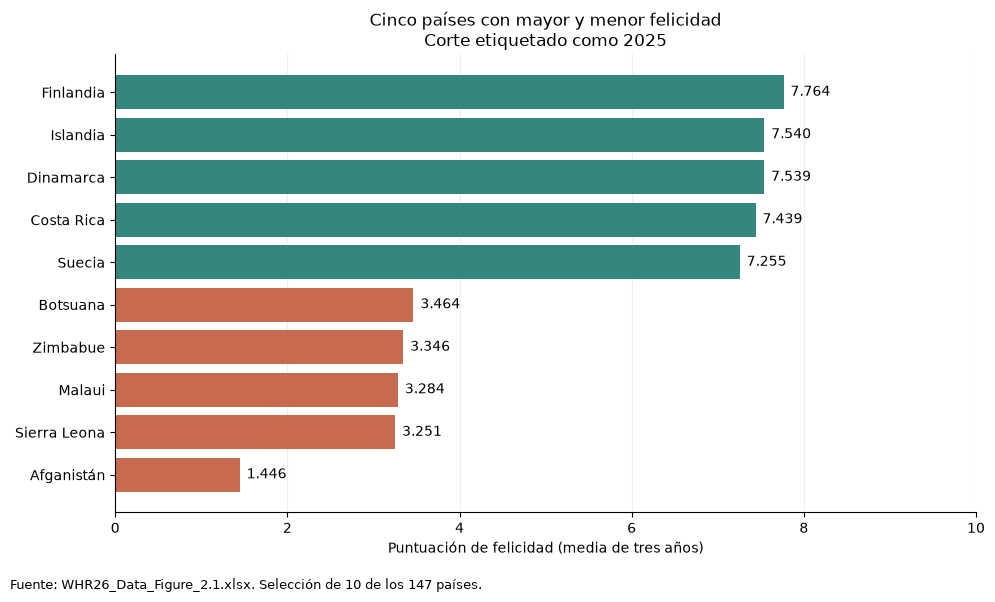

Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\felicidad_extremos_2025.png


In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# Selecciono los cinco países de cada extremo y ordeno sus puntuaciones.
columna = "felicidad_media_3_anios"

extremos = pd.concat([
    df_actual.nsmallest(5, columna),
    df_actual.nlargest(5, columna)
]).sort_values(columna)

# Distingo los dos grupos con colores y mantengo la escala completa.
colores = ["#C76B50"] * 5 + ["#34877C"] * 5

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(extremos["pais"], extremos[columna], color=colores)

ax.bar_label(barras, fmt="%.3f", padding=5)
ax.set_xlim(0, 10)
ax.set_xlabel("Puntuación de felicidad (media de tres años)")
ax.set_title(
    f"Cinco países con mayor y menor felicidad\n"
    f"Corte etiquetado como {anio_actual}"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx. Selección de 10 de los 147 países.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.04, 1, 1])

# Guardo el gráfico para utilizarlo después en el informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures" / "felicidad_extremos_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", ruta_grafico)

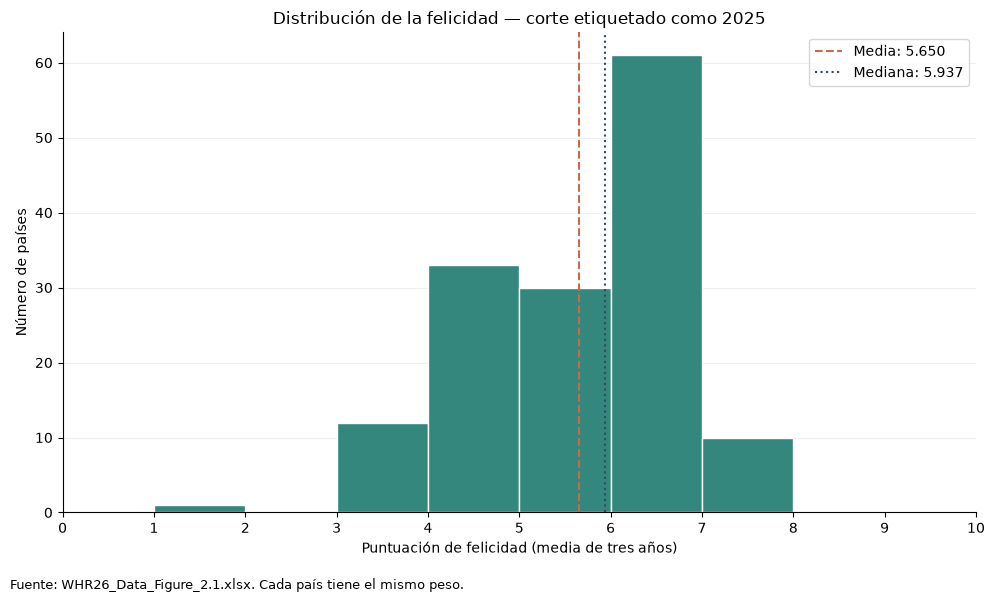

Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\distribucion_felicidad_2025.png


In [44]:
# Examino la distribución de las puntuaciones entre países.
felicidad = df_actual["felicidad_media_3_anios"]

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    felicidad,
    bins=10,
    range=(0, 10),
    color="#34877C",
    edgecolor="white"
)

# Marco la media y la mediana para facilitar la comparación.
ax.axvline(
    felicidad.mean(), color="#C76B50", linestyle="--",
    label=f"Media: {felicidad.mean():.3f}"
)
ax.axvline(
    felicidad.median(), color="#34495E", linestyle=":",
    label=f"Mediana: {felicidad.median():.3f}"
)

ax.set(
    title=f"Distribución de la felicidad — corte etiquetado como {anio_actual}",
    xlabel="Puntuación de felicidad (media de tres años)",
    ylabel="Número de países",
    xlim=(0, 10)
)
ax.set_xticks(range(11))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx. Cada país tiene el mismo peso.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.04, 1, 1])

# Guardo la figura para incorporarla al informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures"
    / "distribucion_felicidad_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", ruta_grafico)

In [45]:
import numpy as np # Cuento los países en los mismos intervalos del histograma.
conteos, limites = np.histogram(
    df_actual["felicidad_media_3_anios"],
    bins=10,
    range=(0, 10)
)

tabla_distribucion = pd.DataFrame({
    "intervalo": [
        f"{int(limites[i])}–{int(limites[i + 1])}"
        for i in range(len(conteos))
    ],
    "numero_paises": conteos
})

tabla_distribucion["porcentaje"] = (
    tabla_distribucion["numero_paises"] / len(df_actual) * 100
).round(2)

display(tabla_distribucion)

,intervalo,numero_paises,porcentaje
0,0–1,0,0.00
1,1–2,1,0.68
2,2–3,0,0.00
3,3–4,12,8.16
4,4–5,33,22.45
5,5–6,30,20.41
6,6–7,61,41.50
7,7–8,10,6.80
8,8–9,0,0.00
9,9–10,0,0.00


### Distribución de las puntuaciones de felicidad

Observo que el intervalo más frecuente es de 6 a menos de 7 puntos: reúne 61 países, el 41,50 % del total.

Entre 5 y menos de 7 puntos se concentran 91 de los 147 países (61,90 %). Por debajo de 4 puntos encuentro 13 países (8,84 %), mientras que 10 países (6,80 %) alcanzan entre 7 y menos de 8 puntos.

Afganistán es el único país con una puntuación inferior a 3. Las puntuaciones bajas alargan la distribución hacia la izquierda, en consonancia con una media (5,650) inferior a la mediana (5,937).

Estos porcentajes representan países, no población. Los intervalos sirven para describir la distribución; no son categorías oficiales de felicidad.

In [46]:
# Calculo las correlaciones de Pearson usando los mismos 145 países.
columna_felicidad = "felicidad_media_3_anios"

matriz_correlaciones = df_factores[
    [columna_felicidad] + list(columnas_factores)
].corr(method="pearson")

correlaciones_felicidad = (
    matriz_correlaciones[columna_felicidad]
    .drop(columna_felicidad)
    .sort_values(ascending=False)
    .rename_axis("factor")
    .reset_index(name="correlacion_pearson")
)

display(correlaciones_felicidad.round(3))

# Guardo los resultados para incorporarlos al informe.
ruta_tabla = (
    carpeta_proyecto / "reports" / "tables"
    / "correlaciones_felicidad_2025.csv"
)
correlaciones_felicidad.to_csv(
    ruta_tabla, index=False, encoding="utf-8-sig"
)

print("Países analizados:", len(df_factores))
print("Tabla guardada:", ruta_tabla)

,factor,correlacion_pearson
0,aporte_apoyo_social,0.812
1,aporte_pib,0.745
2,aporte_vida_saludable,0.679
3,aporte_libertad,0.638
4,aporte_corrupcion,0.396
5,aporte_generosidad,0.038


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\PC\\Documents\\Proyecto 6\\reports\\tables\\correlaciones_felicidad_2025.csv'

### Relación entre los aportes del modelo y la felicidad

Calculo la correlación de Pearson sobre los 145 países con los seis factores completos, utilizando la misma muestra para todas las comparaciones.

- El aporte del apoyo social presenta la mayor correlación positiva con la felicidad (0,812), seguido del aporte del PIB (0,745).
- Los aportes de vida saludable (0,679) y libertad (0,638) también muestran una asociación positiva.
- El aporte asociado a la corrupción presenta una correlación positiva menor (0,396). No lo interpreto como que una mayor corrupción implique mayor felicidad: esta columna representa un aporte del modelo, no una medida directa de corrupción.
- El aporte de generosidad muestra una correlación lineal cercana a cero (0,038). Esto no demuestra que la generosidad carezca de importancia ni descarta relaciones no lineales.

En esta muestra, el apoyo social destaca como el aporte más asociado linealmente con la puntuación de felicidad. Estas correlaciones no demuestran causalidad ni permiten separar el efecto propio de cada factor.

Además, las variables analizadas son componentes de la descomposición de la puntuación del informe. Por ello, estas asociaciones deben interpretarse como descriptivas, no como una validación independiente del modelo.

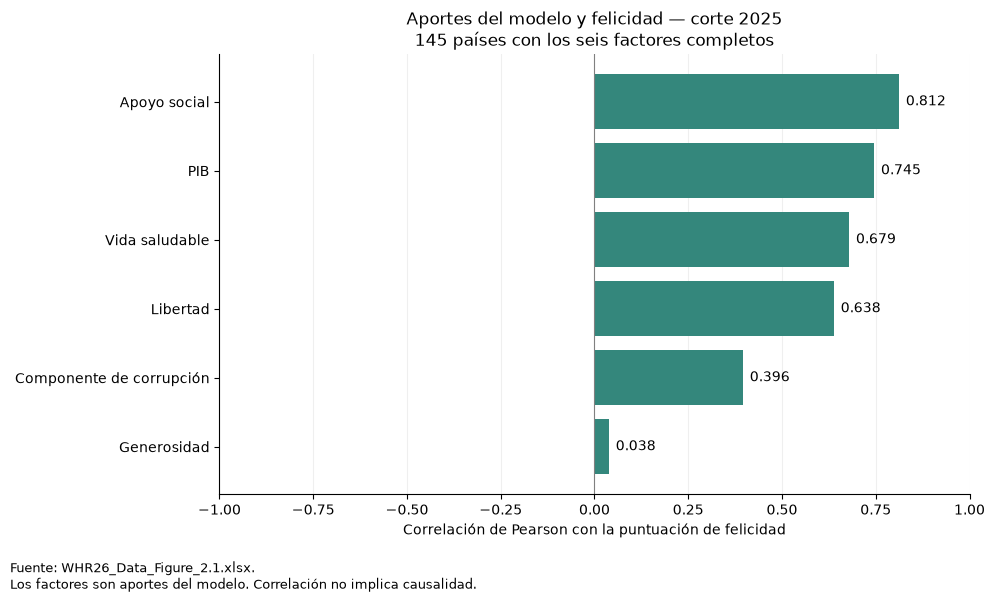

Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\correlaciones_felicidad_2025.png


In [ ]:
# Ordeno las correlaciones para comparar visualmente los seis aportes.
datos_grafico = correlaciones_felicidad.sort_values("correlacion_pearson")

etiquetas = {
    "aporte_apoyo_social": "Apoyo social",
    "aporte_pib": "PIB",
    "aporte_vida_saludable": "Vida saludable",
    "aporte_libertad": "Libertad",
    "aporte_corrupcion": "Componente de corrupción",
    "aporte_generosidad": "Generosidad"
}

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    datos_grafico["factor"].map(etiquetas),
    datos_grafico["correlacion_pearson"],
    color="#34877C"
)

ax.bar_label(barras, fmt="%.3f", padding=5)
ax.set_xlim(-1, 1)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Correlación de Pearson con la puntuación de felicidad")
ax.set_title(
    f"Aportes del modelo y felicidad — corte {anio_actual}\n"
    "145 países con los seis factores completos"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx.\n"
    "Los factores son aportes del modelo. Correlación no implica causalidad.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.07, 1, 1])

# Guardo el gráfico para el informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures"
    / "correlaciones_felicidad_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", ruta_grafico)

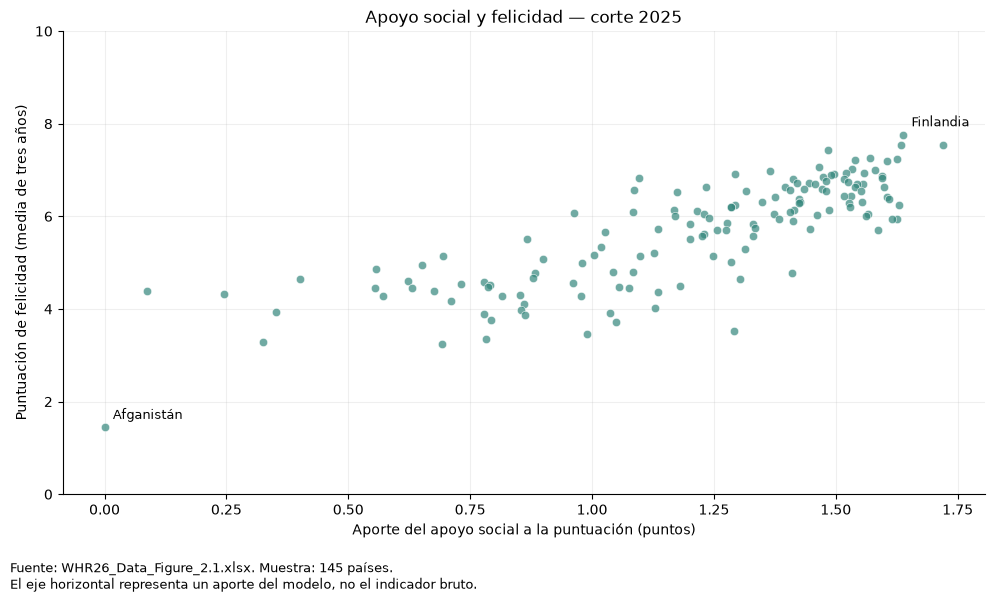

Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\dispersion_apoyo_social_felicidad_2025.png


In [ ]:
# Examino la relación con el aporte que presentó mayor correlación.
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_factores["aporte_apoyo_social"],
    df_factores["felicidad_media_3_anios"],
    color="#34877C",
    alpha=0.7,
    edgecolors="white",
    linewidths=0.5
)

# Identifico los países con mayor y menor felicidad de esta muestra.
indices_destacados = [
    df_factores["felicidad_media_3_anios"].idxmax(),
    df_factores["felicidad_media_3_anios"].idxmin()
]

for indice in indices_destacados:
    fila = df_factores.loc[indice]
    ax.annotate(
        fila["pais"],
        (fila["aporte_apoyo_social"], fila["felicidad_media_3_anios"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set(
    title=f"Apoyo social y felicidad — corte {anio_actual}",
    xlabel="Aporte del apoyo social a la puntuación (puntos)",
    ylabel="Puntuación de felicidad (media de tres años)",
    ylim=(0, 10)
)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx. Muestra: 145 países.\n"
    "El eje horizontal representa un aporte del modelo, no el indicador bruto.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.07, 1, 1])

# Guardo la figura para utilizarla en el informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures"
    / "dispersion_apoyo_social_felicidad_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", ruta_grafico)

In [ ]:
# Resumo la puntuación y la cobertura de países por año.
resumen_temporal = (
    df.groupby("anio")
    .agg(
        numero_paises=("pais", "nunique"),
        media_felicidad=("felicidad_media_3_anios", "mean"),
        mediana_felicidad=("felicidad_media_3_anios", "median")
    )
    .reset_index()
    .sort_values("anio")
)

display(resumen_temporal.round(3))

# Guardo el resumen para documentar la comparación temporal.
ruta_tabla = (
    carpeta_proyecto / "reports" / "tables"
    / "resumen_temporal_felicidad.csv"
)
resumen_temporal.to_csv(
    ruta_tabla, index=False, encoding="utf-8-sig"
)

print("Tabla guardada:", ruta_tabla)

,anio,numero_paises,media_felicidad,mediana_felicidad
0,2011,156,5.392,5.230
1,2012,156,5.419,5.326
2,2014,158,5.376,5.232
3,2015,157,5.382,5.314
4,2016,155,5.354,5.279
5,2017,156,5.376,5.378
6,2018,156,5.407,5.380
7,2019,153,5.473,5.515
8,2020,149,5.533,5.534
9,2021,146,5.554,5.568


Tabla guardada: C:\Users\PC\Documents\Proyecto 6\reports\tables\resumen_temporal_felicidad.csv


In [ ]:
print(resumen_temporal.round(3).to_string(index=False))

 anio  numero_paises  media_felicidad  mediana_felicidad
 2011            156            5.392              5.230
 2012            156            5.419              5.326
 2014            158            5.376              5.232
 2015            157            5.382              5.314
 2016            155            5.354              5.279
 2017            156            5.376              5.378
 2018            156            5.407              5.380
 2019            153            5.473              5.515
 2020            149            5.533              5.534
 2021            146            5.554              5.568
 2022            137            5.540              5.684
 2023            143            5.528              5.785
 2024            147            5.578              5.868
 2025            147            5.650              5.937


In [ ]:
# Comparo los mismos países para evitar diferencias de cobertura.
columna = "felicidad_media_3_anios"

comparacion_2019_2025 = (
    df.loc[df["anio"] == 2019, ["pais", columna]]
    .rename(columns={columna: "felicidad_2019"})
    .merge(
        df.loc[df["anio"] == 2025, ["pais", columna]]
        .rename(columns={columna: "felicidad_2025"}),
        on="pais",
        how="inner",
        validate="one_to_one"
    )
)

# Calculo el cambio en puntos, no en porcentaje.
comparacion_2019_2025["cambio_puntos"] = (
    comparacion_2019_2025["felicidad_2025"]
    - comparacion_2019_2025["felicidad_2019"]
)

print("Países comunes:", len(comparacion_2019_2025))
print(
    "Media de 2019:",
    round(comparacion_2019_2025["felicidad_2019"].mean(), 3)
)
print(
    "Media de 2025:",
    round(comparacion_2019_2025["felicidad_2025"].mean(), 3)
)
print(
    "Cambio medio en puntos:",
    round(comparacion_2019_2025["cambio_puntos"].mean(), 3)
)

# Compruebo qué países quedan fuera por cobertura o cambios de nombre.
paises_2019 = set(df.loc[df["anio"] == 2019, "pais"])
paises_2025 = set(df.loc[df["anio"] == 2025, "pais"])

print("\nSolo en 2019:", sorted(paises_2019 - paises_2025))
print("Solo en 2025:", sorted(paises_2025 - paises_2019))

Países comunes: 144
Media de 2019: 5.548
Media de 2025: 5.647
Cambio medio en puntos: 0.099

Solo en 2019: ['Bielorrusia', 'Burundi', 'Chipre del Norte', 'Haití', 'Maldivas', 'República Centroafricana', 'Ruanda', 'Sudán del Sur', 'Turkmenistán']
Solo en 2025: ['Belice', 'Omán', 'Somalia']


In [ ]:
# Unifico el nombre del país y conservo pais_original como referencia.
for tabla in [df, df_actual, df_factores]:
    tabla["pais"] = tabla["pais"].replace({"Suazilandia": "Esuatini"})

# Compruebo que la unificación no genera duplicados por país y año.
duplicados = df.duplicated(subset=["pais", "anio"]).sum()
print("Duplicados por país y año tras unificar:", duplicados)

# Actualizo los archivos procesados con el nombre unificado.
if duplicados == 0:
    for nombre, tabla in [
        ("felicidad_historico_es.csv", df),
        ("felicidad_2025_es.csv", df_actual),
        ("felicidad_2025_factores_completos_es.csv", df_factores)
    ]:
        tabla.to_csv(
            carpeta_proyecto / "data" / "processed" / nombre,
            index=False,
            encoding="utf-8-sig"
        )
    print("Archivos procesados actualizados.")
else:
    print("Reviso los duplicados antes de continuar.")

Duplicados por país y año tras unificar: 0
Archivos procesados actualizados.


In [ ]:
# Guardo la comparación con los nombres de países unificados.
ruta_tabla = (
    carpeta_proyecto / "reports" / "tables"
    / "comparacion_felicidad_2019_2025.csv"
)
comparacion_2019_2025.to_csv(
    ruta_tabla, index=False, encoding="utf-8-sig"
)

# Identifico los mayores aumentos y descensos en puntos.
print("Cinco países con mayor aumento:")
print(
    comparacion_2019_2025.nlargest(5, "cambio_puntos")
    .round(3).to_string(index=False)
)

print("\nCinco países con mayor descenso:")
print(
    comparacion_2019_2025.nsmallest(5, "cambio_puntos")
    .round(3).to_string(index=False)
)

print("\nTabla guardada:", ruta_tabla)

Cinco países con mayor aumento:
   pais  felicidad_2019  felicidad_2025  cambio_puntos
Vietnam           5.353           6.428          1.075
  India           3.573           4.536          0.963
  China           5.124           6.074          0.950
 Serbia           5.778           6.691          0.913
Armenia           4.677           5.584          0.907

Cinco países con mayor descenso:
               pais  felicidad_2019  felicidad_2025  cambio_puntos
         Afganistán           2.567           1.446         -1.121
             Líbano           4.772           3.723         -1.049
           Pakistán           5.693           4.868         -0.825
              Benín           5.216           4.393         -0.823
República del Congo           5.194           4.456         -0.738

Tabla guardada: C:\Users\PC\Documents\Proyecto 6\reports\tables\comparacion_felicidad_2019_2025.csv


### Comparación de los cortes 2019 y 2025

Comparo los 144 países presentes en ambos cortes, después de unificar Suazilandia y Esuatini bajo el nombre Esuatini. Conservo el nombre de la fuente en pais_original y compruebo que la unificación no genera duplicados por país y año.

En esta muestra común, la media pasa de 5,548 a 5,647 puntos: un aumento de 0,099 puntos, dando el mismo peso a cada país.

Los mayores aumentos corresponden a Vietnam (+1,075), India (+0,963), China (+0,950), Serbia (+0,913) y Armenia (+0,907).

Los mayores descensos corresponden a Afganistán (−1,121), Líbano (−1,049), Pakistán (−0,825), Benín (−0,823) y República del Congo (−0,738).

Observo que el pequeño aumento medio oculta diferencias importantes en la evolución de los países. Comparo puntuaciones calculadas como medias de tres años, no mediciones de dos años aislados.

Estos cambios son descriptivos: no he evaluado su significación estadística ni puedo atribuirlos a causas concretas con este análisis. El corte etiquetado como 2019 corresponde al período 2017–2019,
publicado en el World Happiness Report 2020. Por tanto, comparo
2017–2019 con 2023–2025, manteniendo los 144 países comunes.

Distingo este corte del informe publicado en 2019, cuyo ranking
corresponde a 2016–2018. Los materiales de esa edición no son
la base de esta comparación.

Fuente:
https://www.worldhappiness.report/ed/2020/social-environments-for-world-happiness/

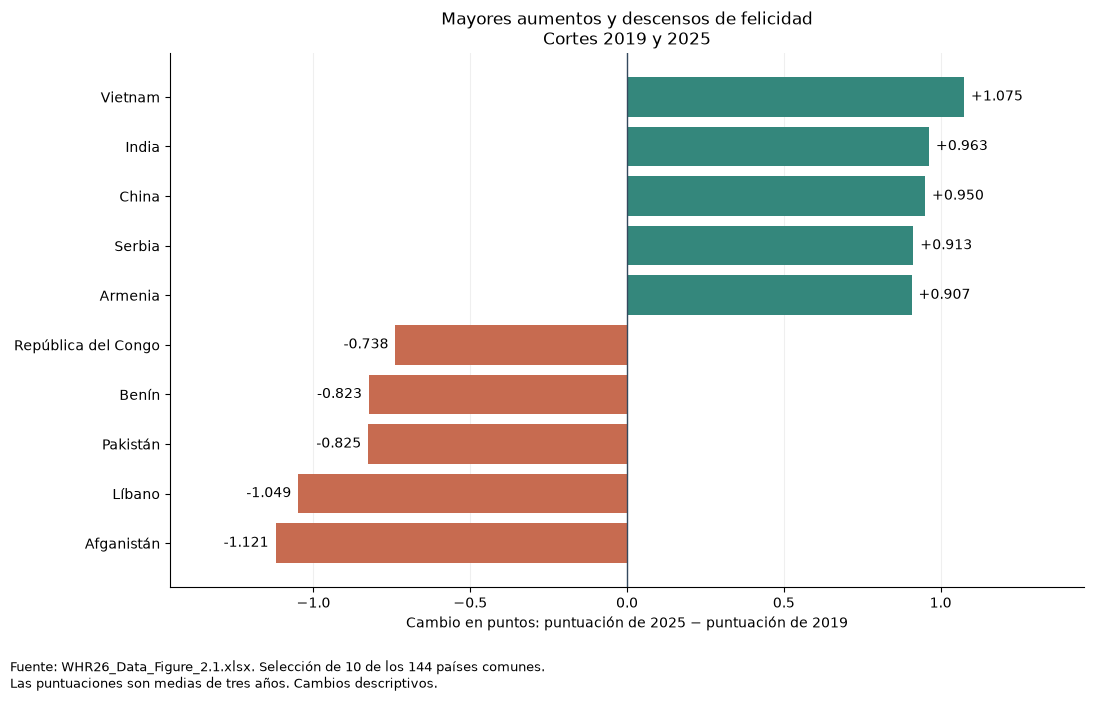

Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\cambios_felicidad_2019_2025.png


In [ ]:
# Selecciono los cinco mayores descensos y los cinco mayores aumentos.
cambios_destacados = pd.concat([
    comparacion_2019_2025.nsmallest(5, "cambio_puntos"),
    comparacion_2019_2025.nlargest(5, "cambio_puntos")
]).sort_values("cambio_puntos")

colores = [
    "#C76B50" if cambio < 0 else "#34877C"
    for cambio in cambios_destacados["cambio_puntos"]
]

fig, ax = plt.subplots(figsize=(11, 7))

barras = ax.barh(
    cambios_destacados["pais"],
    cambios_destacados["cambio_puntos"],
    color=colores
)

ax.bar_label(barras, fmt="%+.3f", padding=5)
ax.axvline(0, color="#34495E", linewidth=1)

# Uso límites simétricos para comparar aumentos y descensos.
limite = cambios_destacados["cambio_puntos"].abs().max() * 1.3
ax.set_xlim(-limite, limite)
ax.set_xlabel("Cambio en puntos: puntuación de 2025 − puntuación de 2019")
ax.set_title("Mayores aumentos y descensos de felicidad\nCortes 2019 y 2025")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx. Selección de 10 de los 144 países comunes.\n"
    "Las puntuaciones son medias de tres años. Cambios descriptivos.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.07, 1, 1])

# Guardo el gráfico para el informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures"
    / "cambios_felicidad_2019_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", ruta_grafico)

In [ ]:
# Cuento los cambios según las puntuaciones disponibles en el archivo.
cambios = comparacion_2019_2025["cambio_puntos"]

balance_cambios = pd.DataFrame({
    "resultado": ["Aumento", "Descenso", "Sin cambio"],
    "numero_paises": [
        (cambios > 0).sum(),
        (cambios < 0).sum(),
        (cambios == 0).sum()
    ]
})

balance_cambios["porcentaje"] = (
    balance_cambios["numero_paises"] / len(cambios) * 100
).round(2)

print(balance_cambios.to_string(index=False))
print("\nCambio mediano en puntos:", round(cambios.median(), 3))

# Guardo el balance para el informe.
ruta_tabla = (
    carpeta_proyecto / "reports" / "tables"
    / "balance_cambios_2019_2025.csv"
)
balance_cambios.to_csv(
    ruta_tabla, index=False, encoding="utf-8-sig"
)

print("\nTabla guardada:", ruta_tabla)

 resultado  numero_paises  porcentaje
   Aumento             90        62.5
  Descenso             54        37.5
Sin cambio              0         0.0

Cambio mediano en puntos: 0.09

Tabla guardada: C:\Users\PC\Documents\Proyecto 6\reports\tables\balance_cambios_2019_2025.csv


### Balance de los cambios entre 2019 y 2025

Entre los 144 países comunes, identifico 90 con aumento de puntuación (62,5 %) y 54 con descenso (37,5 %). Ninguno presenta exactamente la misma puntuación en ambos cortes según los valores del archivo.

El cambio mediano es de +0,090 puntos: la mitad de los países presenta cambios iguales o inferiores a ese valor y la otra mitad, iguales o superiores. El cambio medio es de +0,099 puntos.

Aunque los aumentos son más frecuentes, estos resultados no significan que el 62,5 % de la población mundial haya mejorado: la unidad de análisis es el país y no pondero por población.

Clasifico los cambios por su signo, sin aplicar un umbral mínimo ni una prueba de significación estadística. Por tanto, un aumento pequeño no demuestra por sí solo una mejora relevante.

### Verificación de la fuente y del periodo analizado

El archivo WHR26_Data_Figure_2.1.xlsx pertenece al World Happiness Report 2026.

Confirmo en la figura 2.1 del informe que el ranking utiliza evaluaciones de vida del periodo 2023–2025. La puntuación de Finlandia (7,764) coincide con el corte etiquetado como 2025 en el archivo.

Por tanto, en el análisis principal distingo:
- Año de publicación del informe: 2026.
- Periodo de las evaluaciones: 2023–2025.
- Etiqueta utilizada en la columna anio: 2025.

Los nombres de archivo terminados en 2025 identifican el corte del conjunto de datos, no la edición del informe. En los entregables indicaré «Periodo 2023–2025 · Informe 2026».

Fuente oficial:
https://www.worldhappiness.report/ed/2026/international-evidence-on-happiness-and-social-media/

In [ ]:
# Reviso el aporte del PIB de Venezuela en todo el histórico.
revision_venezuela = df.loc[
    df["pais"] == "Venezuela",
    ["anio", "pais", "felicidad_media_3_anios", "aporte_pib"]
].sort_values("anio")

print(revision_venezuela.to_string(index=False))

 anio      pais  felicidad_media_3_anios  aporte_pib
 2011 Venezuela                   6.9220         NaN
 2012 Venezuela                   7.0390         NaN
 2014 Venezuela                   6.8100         NaN
 2015 Venezuela                   6.0840         NaN
 2016 Venezuela                   5.2500         NaN
 2017 Venezuela                   4.8060         NaN
 2018 Venezuela                   4.7070         NaN
 2019 Venezuela                   5.0532    0.770239
 2020 Venezuela                   4.8920    0.852000
 2021 Venezuela                   4.9250    0.000000
 2022 Venezuela                   5.2110    0.000000
 2023 Venezuela                   5.6070    0.000000
 2024 Venezuela                   5.6830    0.000000
 2025 Venezuela                   5.7560    0.000000


In [ ]:
# Busco Venezuela en los datos originales, sin traducir ni modificar.
filas_venezuela_original = df_original[
    df_original.astype(str).apply(
        lambda columna: columna.str.contains(
            "Venezuela", case=False, na=False
        )
    ).any(axis=1)
]

print(filas_venezuela_original.to_string(index=False))

 Year  Rank Country name  Life evaluation (3-year average)  Lower whisker  Upper whisker  Explained by: Log GDP per capita  Explained by: Social support  Explained by: Healthy life expectancy  Explained by: Freedom to make life choices  Explained by: Generosity  Explained by: Perceptions of corruption  Dystopia + residual
 2025    80    Venezuela                            5.7560        5.64600        5.86600                          0.000000                      1.335000                               0.561000                                    0.846000                  0.180000                                 0.133000             2.701000
 2024    82    Venezuela                            5.6830        5.57000        5.79600                          0.000000                      1.493000                               0.515000                                    0.702000                  0.154000                                 0.117000             2.701000
 2023    79    Venezuela    

### Revisión del aporte del PIB de Venezuela

Compruebo que el aporte del PIB de Venezuela figura como 0 en los cortes de 2021 a 2025 del archivo original. Por tanto, estos valores no proceden de la traducción ni de la limpieza.

Conservo los valores publicados, sin sustituirlos por estimaciones ni convertirlos automáticamente en nulos. Esta variable representa un aporte del modelo explicativo: un valor cero no significa que el PIB real del país sea cero.

La comprobación confirma la procedencia de los valores, pero no explica su causa. Queda pendiente encontrar una aclaración metodológica en la documentación de la fuente.

Como este caso puede influir en la correlación entre el aporte del PIB y la felicidad, compararé el resultado con y sin Venezuela como análisis de sensibilidad, sin eliminar el país del conjunto principal.

In [ ]:
# Compruebo cuánto cambia la correlación al excluir solo Venezuela.
sin_venezuela = df_factores.loc[df_factores["pais"] != "Venezuela"]

sensibilidad_pib = pd.DataFrame({
    "muestra": ["Con Venezuela", "Sin Venezuela"],
    "numero_paises": [len(df_factores), len(sin_venezuela)],
    "correlacion_pearson": [
        df_factores["aporte_pib"].corr(
            df_factores["felicidad_media_3_anios"]
        ),
        sin_venezuela["aporte_pib"].corr(
            sin_venezuela["felicidad_media_3_anios"]
        )
    ]
})

print(sensibilidad_pib.round(4).to_string(index=False))

# Guardo la comprobación sin modificar el conjunto principal.
sensibilidad_pib.to_csv(
    carpeta_proyecto / "reports" / "tables" / "sensibilidad_pib_venezuela.csv",
    index=False,
    encoding="utf-8-sig"
)

      muestra  numero_paises  correlacion_pearson
Con Venezuela            145               0.7455
Sin Venezuela            144               0.7992


### Análisis de sensibilidad: aporte del PIB de Venezuela

Comparo la correlación de Pearson entre el aporte del PIB y la felicidad con y sin Venezuela:

- Con Venezuela: 0,7455, sobre 145 países.
- Sin Venezuela: 0,7992, sobre 144 países.

Al excluir este caso, la correlación aumenta aproximadamente 0,0537. La asociación sigue siendo positiva y elevada en ambas muestras, aunque su intensidad es sensible a esta observación.

Mantengo Venezuela en el análisis principal porque el cero procede del archivo original y no he confirmado que sea un error. Presento su exclusión únicamente como comprobación de sensibilidad, no como una forma de mejorar el resultado.

Esta comparación no explica el origen del cero ni demuestra una relación causal entre PIB y felicidad.

In [ ]:
# Localizo los documentos de apoyo y los materiales de referencia.
for archivo in sorted(carpeta_proyecto.rglob("*")):
    if archivo.is_file() and archivo.suffix.lower() in {".pdf", ".zip"}:
        print(archivo.relative_to(carpeta_proyecto))

.venv\Lib\site-packages\matplotlib\mpl-data\images\back.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\filesave.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\forward.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\hand.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\help.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\home.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\matplotlib.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\move.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\qt4_editor_options.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\subplots.pdf
.venv\Lib\site-packages\matplotlib\mpl-data\images\zoom_to_rect.pdf
2022-GNH-Survey-Report_compressed.pdf
Materiales_EDA_Felicidad_2019.zip
Proyecto_EDA_Felicidad_2019.pdf


### Bután: otra forma de medir el bienestar

![Bután: otra forma de medir el bienestar](../reports/figures/banner_butan.png)

Incorporo el informe de Felicidad Nacional Bruta de Bután de 2022 como caso complementario.

El World Happiness Report utiliza una evaluación de la propia vida en una escala de 0 a 10. Sus seis factores ayudan a explicar las diferencias entre países, pero no son las preguntas que determinan directamente la puntuación del ranking.

Bután utiliza un índice multidimensional de Felicidad Nacional Bruta (GNH), compuesto por 33 indicadores agrupados en nueve dimensiones.

En 2022:
- El índice GNH fue de 0,781 en una escala de 0 a 1.
- El 48,1 % de la población de 15 años o más fue clasificada como extensa o profundamente feliz.
- Esta clasificación requiere alcanzar suficiencia en al menos el 66 % de los indicadores ponderados.

Distingo el valor del índice del porcentaje de personas clasificadas como felices: 0,781 no significa que el 78,1 % de la población sea feliz.

No convierto el índice en una puntuación de 7,81 ni lo incorporo al ranking mundial, porque ambos sistemas miden el bienestar de forma diferente y corresponden a periodos distintos.

Este caso muestra que la forma de definir y medir la felicidad influye en las conclusiones. Lo utilizo como contexto metodológico, no para completar valores ausentes.

Fuente: 2022 GNH Survey Report, páginas impresas 4, 14 y 22.
Archivo: 2022-GNH-Survey-Report_compressed.pdf.

In [ ]:
# Compruebo la disponibilidad de los países que quiero destacar.
paises_interes = [
    "Colombia", "Cuba", "España", "Argentina",
    "Chile", "Marruecos", "Ucrania"
]

for pais in paises_interes:
    historico_pais = df.loc[df["pais"] == pais]
    datos_actuales = df_actual.loc[df_actual["pais"] == pais]

    print(f"\n{pais}:")

    if historico_pais.empty:
        print("  No aparece con este nombre en el histórico.")
    else:
        anios = sorted(historico_pais["anio"].unique())
        print("  Años disponibles:", ", ".join(str(int(a)) for a in anios))

    if datos_actuales.empty:
        print("  Sin datos en el corte 2025.")
    else:
        print(datos_actuales[
            ["pais", "posicion", "felicidad_media_3_anios"]
        ].to_string(index=False))


Colombia:
  Años disponibles: 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
    pais  posicion  felicidad_media_3_anios
Colombia        68                     6.04

Cuba:
  Años disponibles: 2011
  Sin datos en el corte 2025.

España:
  Años disponibles: 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
  pais  posicion  felicidad_media_3_anios
España        41                     6.54

Argentina:
  Años disponibles: 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
     pais  posicion  felicidad_media_3_anios
Argentina        44                     6.43

Chile:
  Años disponibles: 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
 pais  posicion  felicidad_media_3_anios
Chile        50                    6.302

Marruecos:
  Años disponibles: 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025
     pais  posicion  felici

In [ ]:
# Reviso el único registro disponible de Cuba sin mezclarlo con 2025.
print(
    df.loc[
        df["pais"] == "Cuba",
        ["anio", "pais", "posicion", "felicidad_media_3_anios"]
    ].to_string(index=False)
)

 anio pais  posicion  felicidad_media_3_anios
 2011 Cuba        69                    5.418


### Países de especial interés y disponibilidad de datos

Selecciono Colombia, Cuba, España, Argentina, Chile, Marruecos y Ucrania por interés personal. Esta selección no constituye una muestra representativa del mundo.

España, Argentina, Chile, Colombia, Ucrania y Marruecos tienen datos en el corte 2025, correspondiente al periodo 2023–2025 del informe 2026.

| País | Posición en el ranking | Puntuación |
|---|---:|---:|
| España | 41 | 6,540 |
| Argentina | 44 | 6,430 |
| Chile | 50 | 6,302 |
| Colombia | 68 | 6,040 |
| Ucrania | 111 | 4,658 |
| Marruecos | 112 | 4,646 |

Las posiciones corresponden al ranking completo, no únicamente a esta selección.

Cuba solo aparece en este archivo con la etiqueta 2011, una puntuación de 5,418 y posición 69. No interpreto esa etiqueta como el año exacto de la encuesta. El primer World Happiness Report utilizó datos disponibles entre 2005 y mediados de 2011, pero todavía no he verificado la fecha concreta del dato cubano.

Referencia: [World Happiness Report 2013, página 13](https://files.worldhappiness.report/WHR13.pdf).

No comparo directamente ese registro histórico con las puntuaciones actuales ni lo utilizo para estimar la situación presente de Cuba. Su ausencia en 2025 es una limitación de cobertura del archivo, no una puntuación de cero ni una prueba sobre su nivel actual de felicidad.

In [ ]:
# Comparo los países de interés con datos del mismo periodo.
seleccion_paises = df_actual.loc[
    df_actual["pais"].isin(paises_interes)
].sort_values("felicidad_media_3_anios")

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    seleccion_paises["pais"],
    seleccion_paises["felicidad_media_3_anios"],
    color="#34877C"
)
ax.bar_label(barras, fmt="%.3f", padding=5)

# Añado la media de los 147 países como referencia sin ponderar.
media_referencia = df_actual["felicidad_media_3_anios"].mean()
ax.axvline(
    media_referencia,
    color="#C76B50",
    linestyle="--",
    label=f"Media de los 147 países: {media_referencia:.3f}"
)

ax.set(
    xlim=(0, 10),
    xlabel="Puntuación de felicidad (media de tres años)",
    title="Países de especial interés\nPeriodo 2023–2025 · Informe 2026"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right")

fig.text(
    0.01, 0.01,
    "Fuente: WHR26_Data_Figure_2.1.xlsx. Selección por interés personal.\n"
    "Cuba no tiene datos en este corte. Media de referencia sin ponderar por población.",
    fontsize=9
)
fig.tight_layout(rect=[0, 0.07, 1, 1])

# Guardo el gráfico y la tabla para el informe.
ruta_grafico = (
    carpeta_proyecto / "reports" / "figures"
    / "paises_interes_felicidad_2025.png"
)
fig.savefig(ruta_grafico, dpi=300, bbox_inches="tight")

seleccion_paises[
    ["pais", "posicion", "felicidad_media_3_anios"]
].to_csv(
    carpeta_proyecto / "reports" / "tables"
    / "paises_interes_felicidad_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

plt.show()
print("Gráfico y tabla guardados.")

NameError: name 'df_actual' is not defined

In [ ]:
# Reviso la evolución de los países de interés con datos en ambos cortes.
evolucion_paises_interes = comparacion_2019_2025.loc[
    comparacion_2019_2025["pais"].isin(paises_interes)
].sort_values("cambio_puntos", ascending=False)

print(evolucion_paises_interes.round(3).to_string(index=False))

# Guardo esta selección para el informe.
evolucion_paises_interes.to_csv(
    carpeta_proyecto / "reports" / "tables"
    / "evolucion_paises_interes_2019_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

     pais  felicidad_2019  felicidad_2025  cambio_puntos
Argentina           5.975           6.430          0.455
   España           6.401           6.540          0.139
  Ucrania           4.561           4.658          0.097
    Chile           6.228           6.302          0.074
 Colombia           6.163           6.040         -0.123
Marruecos           5.095           4.646         -0.449


### Evolución de los países de especial interés

Comparo los seis países seleccionados con datos en los cortes 2019 y 2025:

| País | Cambio en puntos |
|---|---:|
| Argentina | +0,455 |
| España | +0,139 |
| Ucrania | +0,097 |
| Chile | +0,074 |
| Colombia | −0,123 |
| Marruecos | −0,449 |

Argentina registra el mayor aumento y Marruecos el mayor descenso dentro de esta selección. España, Ucrania y Chile también presentan aumentos, mientras que Colombia muestra una reducción.

Estos cambios describen diferencias entre puntuaciones medias de tres años. No he evaluado su significación estadística y no atribuyo las variaciones a acontecimientos concretos.

En particular, el pequeño aumento de Ucrania no permite concluir que la guerra haya mejorado el bienestar ni que carezca de efectos negativos. Esta comparación entre dos cortes no identifica causas ni describe toda la evolución intermedia.

Cuba queda fuera de esta comparación porque el archivo no contiene datos del país en ninguno de los dos cortes.

In [ ]:
# Documento los cambios entre el archivo original y el histórico preparado.
resumen_limpieza = pd.DataFrame({
    "criterio": [
        "Filas",
        "Columnas",
        "Duplicados por país y año",
        "Valores ausentes en todo el conjunto",
        "Valores ausentes en felicidad"
    ],
    "antes": [
        len(df_original),
        df_original.shape[1],
        df_original.duplicated(["Country name", "Year"]).sum(),
        df_original.isna().sum().sum(),
        df_original["Life evaluation (3-year average)"].isna().sum()
    ],
    "despues": [
        len(df),
        df.shape[1],
        df.duplicated(["pais", "anio"]).sum(),
        df.isna().sum().sum(),
        df["felicidad_media_3_anios"].isna().sum()
    ]
})

print(resumen_limpieza.to_string(index=False))

# Distingo el histórico completo de la muestra para analizar factores.
excluidos = len(df_actual) - len(df_factores)

print("\nPaíses en el corte 2025:", len(df_actual))
print("Países con los seis factores completos:", len(df_factores))
print("Excluidos solo del análisis conjunto de factores:", excluidos)
print("Porcentaje excluido:", round(excluidos / len(df_actual) * 100, 2))

# Guardo la tabla para el informe.
resumen_limpieza.to_csv(
    carpeta_proyecto / "reports" / "tables"
    / "resumen_limpieza_antes_despues.csv",
    index=False,
    encoding="utf-8-sig"
)

                            criterio  antes  despues
                               Filas   2116     2116
                            Columnas     13       14
           Duplicados por país y año      0        0
Valores ausentes en todo el conjunto   9879     9879
       Valores ausentes en felicidad      0        0

Países en el corte 2025: 147
Países con los seis factores completos: 145
Excluidos solo del análisis conjunto de factores: 2
Porcentaje excluido: 1.36


### Balance de la limpieza: antes y después

Conservo las 2.116 filas originales: no elimino registros del histórico (0 %). El número de columnas pasa de 13 a 14 porque añado pais_original para mantener los nombres de la fuente.

Traduzco los nombres de columnas y países al español y unifico Suazilandia y Esuatini. Tras esta unificación, siguen existiendo cero duplicados por país y año.

Mantengo los 9.879 valores ausentes del archivo. No los sustituyo por ceros ni por estimaciones: la disponibilidad de información varía entre periodos y factores. La puntuación de felicidad no tiene valores ausentes.

En el corte 2025:
- Conservo los 147 países para analizar la felicidad.
- Utilizo 145 países con los seis factores completos para las correlaciones.
- Excluyo únicamente de ese análisis conjunto a Tayikistán y Estado de Palestina: 2 países, el 1,36 % del corte.
- No elimino estos países del histórico ni del ranking general.

Conservo los valores atípicos detectados, ya que ser estadísticamente inusual no demuestra un error. También mantengo el aporte del PIB igual a cero de Venezuela, presente en el archivo original, y documento su análisis de sensibilidad.

La limpieza mejora la consistencia, la comprensión y la trazabilidad de los datos sin inventar información ni reducir artificialmente los valores ausentes.

In [ ]:
# Verifico que la comparación incluye Esuatini tras unificar su nombre.
assert len(comparacion_2019_2025) == 144, (
    "La comparación debería incluir 144 países."
)
assert "Esuatini" in comparacion_2019_2025["pais"].values, (
    "Falta Esuatini en la comparación."
)

print("Comprobación correcta: 144 países comunes, incluido Esuatini.")

Comprobación correcta: 144 países comunes, incluido Esuatini.


## Conclusiones generales

Mi objetivo fue explorar las diferencias de felicidad entre países y determinar qué aportes del modelo están más relacionados con la puntuación.

1. **Apoyo social y PIB destacan en las asociaciones.** Entre los 145 países con factores completos, el aporte del apoyo social presenta la mayor correlación con la felicidad (0,812), seguido del PIB (0,745). Estas asociaciones no demuestran causalidad y corresponden a aportes del modelo, no a indicadores brutos independientes.

2. **Existen diferencias amplias entre países.** En el periodo 2023–2025, Finlandia registra 7,764 puntos y Afganistán 1,446: una diferencia de 6,318 puntos. La media de los 147 países es 5,650, sin ponderar por población.

3. **El pequeño aumento medio oculta evoluciones distintas.** Entre los cortes 2019 y 2025, los 144 países comunes presentan un cambio medio de +0,099 puntos. Aumentan 90 países y disminuyen 54. No he evaluado la significación estadística de estos cambios.

4. **Los casos particulares requieren revisión.** El aporte del PIB de Venezuela figura como cero en la fuente. Al excluir este país, la correlación PIB-felicidad pasa de 0,7455 a 0,7992. Conservo el país y documento esta sensibilidad.

5. **La cobertura y la definición de felicidad condicionan las conclusiones.** Cuba carece de datos recientes en este archivo. El índice multidimensional de Bután aporta contexto, pero no es directamente comparable con la puntuación del World Happiness Report.

### Límites y próximos pasos

Las medias nacionales no describen las desigualdades dentro de cada país. La cobertura cambia entre cortes y las puntuaciones representan periodos de varios años.

Para profundizar, sería necesario contrastar indicadores brutos, examinar la incertidumbre de las estimaciones y completar las aclaraciones temporales pendientes. Este EDA permite formular preguntas e identificar asociaciones, pero no recomendar intervenciones como si sus efectos estuvieran demostrados.

In [ ]:
from importlib.metadata import version

# Registro las versiones de las dependencias que utiliza mi proyecto.
paquetes = [
    "numpy",
    "pandas",
    "matplotlib",
    "openpyxl",
    "requests",
    "ipykernel",
    "bokeh"
]

contenido = "\n".join(
    f"{paquete}=={version(paquete)}"
    for paquete in paquetes
) + "\n"

ruta_requisitos = carpeta_proyecto / "requirements.txt"
ruta_requisitos.write_text(contenido, encoding="utf-8")

print(contenido)
print("Guardado:", ruta_requisitos)

numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
openpyxl==3.1.5
requests==2.34.2
ipykernel==7.4.0
bokeh==3.10.1

Guardado: C:\Users\PC\Documents\Proyecto 6\requirements.txt


In [ ]:
# Instalo Bokeh para crear los gráficos interactivos del proyecto.
%pip install bokeh

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from bokeh.plotting import figure
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.io import save
from bokeh.resources import INLINE

# Utilizo los mismos 145 países del análisis de correlaciones.
fuente_interactiva = ColumnDataSource(
    df_factores[
        ["pais", "aporte_apoyo_social", "felicidad_media_3_anios"]
    ].copy()
)

grafico_apoyo = figure(
    title=f"Apoyo social y felicidad — {anio_actual}",
    x_axis_label="Aporte del apoyo social (puntos del modelo)",
    y_axis_label="Felicidad: media de tres años (0–10)",
    width=950,
    height=550,
    y_range=(0, 10),
    tools="pan,wheel_zoom,box_zoom,reset,save",
    active_scroll="wheel_zoom"
)

grafico_apoyo.scatter(
    x="aporte_apoyo_social",
    y="felicidad_media_3_anios",
    source=fuente_interactiva,
    size=9,
    color="#287D8E",
    alpha=0.75
)

# Muestro el país y sus valores al pasar el cursor.
grafico_apoyo.add_tools(HoverTool(tooltips=[
    ("País", "@pais"),
    ("Aporte del apoyo social", "@aporte_apoyo_social{0.000}"),
    ("Felicidad", "@felicidad_media_3_anios{0.000}")
]))

# Guardo un HTML que puedo abrir sin conexión a internet.
ruta_interactiva = (
    carpeta_proyecto / "reports" / "figures"
    / f"interactivo_apoyo_social_{anio_actual}.html"
)
ruta_interactiva.parent.mkdir(parents=True, exist_ok=True)

save(
    grafico_apoyo,
    filename=str(ruta_interactiva),
    resources=INLINE,
    title="Apoyo social y felicidad"
)

print("Gráfico interactivo guardado:", ruta_interactiva)

Gráfico interactivo guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\interactivo_apoyo_social_2025.html


In [ ]:
from bokeh.plotting import figure, show, output_file
from bokeh.models import ColumnDataSource, HoverTool

# Comparo las correlaciones de los seis aportes con la felicidad.
correlaciones = (
    df_factores[columnas_factores]
    .corrwith(df_factores["felicidad_media_3_anios"])
    .sort_values()
)

etiquetas = [
    nombre.replace("aporte_", "").replace("_", " ").capitalize()
    for nombre in correlaciones.index
]

fuente_correlaciones = ColumnDataSource(
    data={
        "factor": etiquetas,
        "correlacion": correlaciones.values,
    }
)

grafico_factores = figure(
    y_range=etiquetas,
    x_range=(-1, 1),
    title="Relación de los aportes con la felicidad · Corte 2025",
    x_axis_label="Correlación de Pearson",
    width=950,
    height=500,
    tools="pan,box_zoom,reset,save",
)

barras = grafico_factores.hbar(
    y="factor",
    right="correlacion",
    height=0.65,
    source=fuente_correlaciones,
    color="#247A87",
)

grafico_factores.add_tools(
    HoverTool(
        renderers=[barras],
        tooltips=[
            ("Factor", "@factor"),
            ("Correlación", "@correlacion{0.000}"),
        ],
    )
)

grafico_factores.title.text_font_size = "16pt"
grafico_factores.background_fill_color = "#FAFAFA"
grafico_factores.ygrid.grid_line_color = None

# Guardo el gráfico con los recursos incluidos para consultarlo sin internet.
ruta_factores = (
    carpeta_proyecto
    / "reports"
    / "figures"
    / "interactivo_correlaciones_2025.html"
)
ruta_factores.parent.mkdir(parents=True, exist_ok=True)

output_file(
    str(ruta_factores),
    title="Correlaciones de los factores — 2025",
    mode="inline",
)
show(grafico_factores)

print(f"Gráfico interactivo guardado: {ruta_factores}")

Gráfico interactivo guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\interactivo_correlaciones_2025.html


### Interpretación de las correlaciones

Observo que el aporte del apoyo social presenta la mayor correlación
positiva con la felicidad, seguido del PIB y la vida saludable.
La generosidad muestra una correlación lineal cercana a cero, lo que
no permite descartar otras formas de relación.

Analizo los aportes del modelo WHR, no los indicadores brutos.
Estas correlaciones describen asociaciones entre países y no demuestran
causalidad. El corte 2025 representa la media del período 2023–2025.

## Teorema del límite central

Simulo 5.000 muestras de 30 países, seleccionadas con reemplazo entre
los países del corte 2025. Calculo la felicidad media de cada muestra
para observar cómo se distribuyen esas medias.

Con esta simulación ilustro el teorema del límite central: al aumentar
el tamaño de las muestras, la distribución de sus medias tiende a
aproximarse a una distribución normal.

Cada país tiene el mismo peso. Este ejercicio no representa una
muestra de habitantes del mundo ni incorpora la incertidumbre de
las encuestas originales.

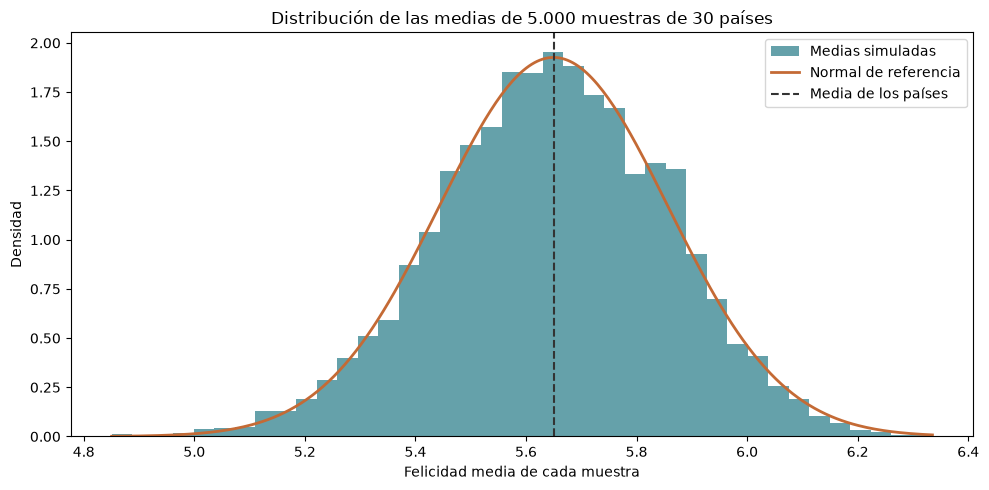

Media de los países: 5.650
Media de las medias simuladas: 5.648
Error estándar teórico: 0.207
Desviación de las medias simuladas: 0.207
Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\teorema_limite_central.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fijo la semilla para poder reproducir los resultados.
rng = np.random.default_rng(42)

valores_felicidad = (
    df_actual["felicidad_media_3_anios"]
    .dropna()
    .to_numpy()
)

n_muestra = 30
n_simulaciones = 5000

# Muestreo con reemplazo: un país puede aparecer varias veces.
muestras = rng.choice(
    valores_felicidad,
    size=(n_simulaciones, n_muestra),
    replace=True,
)
medias_simuladas = muestras.mean(axis=1)

media_paises = valores_felicidad.mean()
error_teorico = valores_felicidad.std(ddof=0) / np.sqrt(n_muestra)

# Comparo las medias simuladas con una curva normal de referencia.
x = np.linspace(
    medias_simuladas.min(),
    medias_simuladas.max(),
    300,
)
densidad_normal = (
    np.exp(-0.5 * ((x - media_paises) / error_teorico) ** 2)
    / (error_teorico * np.sqrt(2 * np.pi))
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    medias_simuladas,
    bins=40,
    density=True,
    color="#247A87",
    alpha=0.7,
    label="Medias simuladas",
)
ax.plot(
    x, densidad_normal,
    color="#C46A35",
    linewidth=2,
    label="Normal de referencia",
)
ax.axvline(
    media_paises,
    color="#333333",
    linestyle="--",
    label="Media de los países",
)

ax.set(
    title="Distribución de las medias de 5.000 muestras de 30 países",
    xlabel="Felicidad media de cada muestra",
    ylabel="Densidad",
)
ax.legend()
fig.tight_layout()

ruta_tlc = carpeta_proyecto / "reports" / "figures" / "teorema_limite_central.png"
ruta_tlc.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_tlc, dpi=150, bbox_inches="tight")
plt.show()

print(f"Media de los países: {media_paises:.3f}")
print(f"Media de las medias simuladas: {medias_simuladas.mean():.3f}")
print(f"Error estándar teórico: {error_teorico:.3f}")
print(f"Desviación de las medias simuladas: {medias_simuladas.std(ddof=1):.3f}")
print(f"Gráfico guardado: {ruta_tlc}")

### Interpretación de la simulación

Obtengo una media de las medias simuladas de 5,648, muy próxima
a la media de los países analizados, de 5,650. La desviación estándar
de las medias simuladas y el error estándar teórico coinciden en
0,207 al redondear a tres decimales.

Estos resultados son coherentes con el comportamiento esperado
de la distribución muestral de la media. La aproximación a una
forma normal se valora también mediante el histograma; la coincidencia
de estas cifras, por sí sola, no demuestra normalidad.

La simulación utiliza el mismo peso para cada país y muestreo con
reemplazo. Por tanto, no interpreto estos resultados como una
estimación de la felicidad media de todos los habitantes del mundo.

## Prueba de hipótesis: apoyo social y felicidad

Compruebo si la correlación observada es compatible con una asignación
aleatoria de los valores de felicidad entre los países analizados.

- H₀: el aporte del apoyo social y la felicidad son independientes;
  los valores de felicidad pueden intercambiarse entre países.
- H₁: existe una asociación, evaluada mediante la correlación de Pearson.

Utilizo una prueba bilateral de permutaciones con 10.000 repeticiones
y un nivel de significación de 0,05. Comparo el valor absoluto de la
correlación observada con los obtenidos al mezclar los datos.

El análisis es exploratorio: seleccioné el apoyo social después de
examinar las correlaciones. Además, utilizo un aporte del modelo WHR,
no el indicador bruto. Los países no constituyen una muestra aleatoria
y pueden compartir características regionales. Estas limitaciones
impiden interpretar el resultado como una prueba causal.

In [ ]:
import numpy as np

# Utilizo únicamente países con ambos valores disponibles.
datos_prueba = df_factores[
    ["aporte_apoyo_social", "felicidad_media_3_anios"]
].dropna()

x_apoyo = datos_prueba["aporte_apoyo_social"].to_numpy()
y_felicidad = datos_prueba["felicidad_media_3_anios"].to_numpy()

r_observado = np.corrcoef(x_apoyo, y_felicidad)[0, 1]

# Mezclo la felicidad para simular la hipótesis de independencia.
rng_prueba = np.random.default_rng(42)
n_permutaciones = 10000
r_permutadas = np.empty(n_permutaciones)

for i in range(n_permutaciones):
    y_mezclada = rng_prueba.permutation(y_felicidad)
    r_permutadas[i] = np.corrcoef(x_apoyo, y_mezclada)[0, 1]

# Incluyo una corrección para que el p-value estimado nunca sea cero.
casos_extremos = np.count_nonzero(
    np.abs(r_permutadas) >= abs(r_observado)
)
p_value = (casos_extremos + 1) / (n_permutaciones + 1)
alpha = 0.05

print(f"Países analizados: {len(datos_prueba)}")
print(f"Correlación observada: {r_observado:.4f}")
print(f"Permutaciones: {n_permutaciones}")
print(f"P-value estimado: {p_value:.6f}")

if p_value < alpha:
    print("Decisión: rechazo H₀ bajo los supuestos de la prueba.")
else:
    print("Decisión: no rechazo H₀ bajo los supuestos de la prueba.")

Países analizados: 145
Correlación observada: 0.8119
Permutaciones: 10000
P-value estimado: 0.000100
Decisión: rechazo H₀ bajo los supuestos de la prueba.


### Interpretación de la prueba de hipótesis

En los 145 países analizados obtengo una correlación de Pearson
de 0,8119 entre el aporte del apoyo social y la felicidad.

La prueba bilateral de 10.000 permutaciones proporciona un p-value
estimado de 0,000100, inferior al nivel de significación de 0,05.
Por ello, rechazo la hipótesis de independencia bajo los supuestos
de la prueba.

Ninguna permutación produjo una correlación de valor absoluto igual
o superior a la observada. El p-value corresponde al mínimo estimable
con estas repeticiones y la corrección aplicada; no significa que
la probabilidad sea cero ni expresa la probabilidad de que H₀ sea cierta.

Interpreto el resultado como evidencia exploratoria de asociación,
no de causalidad. Seleccioné este factor después de examinar las
correlaciones y analizo un aporte del propio modelo WHR. Además,
las semejanzas entre países pueden limitar el supuesto de
intercambiabilidad utilizado en las permutaciones.

## Regresión lineal simple

Ajusto una regresión lineal con el aporte del apoyo social como
variable explicativa y la felicidad como variable respuesta.

Calculo la pendiente, el intercepto, el coeficiente de determinación
R² y la raíz del error cuadrático medio (RMSE). También represento
los residuos: las diferencias entre los valores observados y ajustados.

El objetivo es descriptivo. Evalúo el ajuste sobre los mismos países
utilizados para construir la recta; no considero estas métricas una
validación de predicciones para países nuevos. Tampoco interpreto
la relación como causal, pues utilizo un aporte del propio modelo WHR.

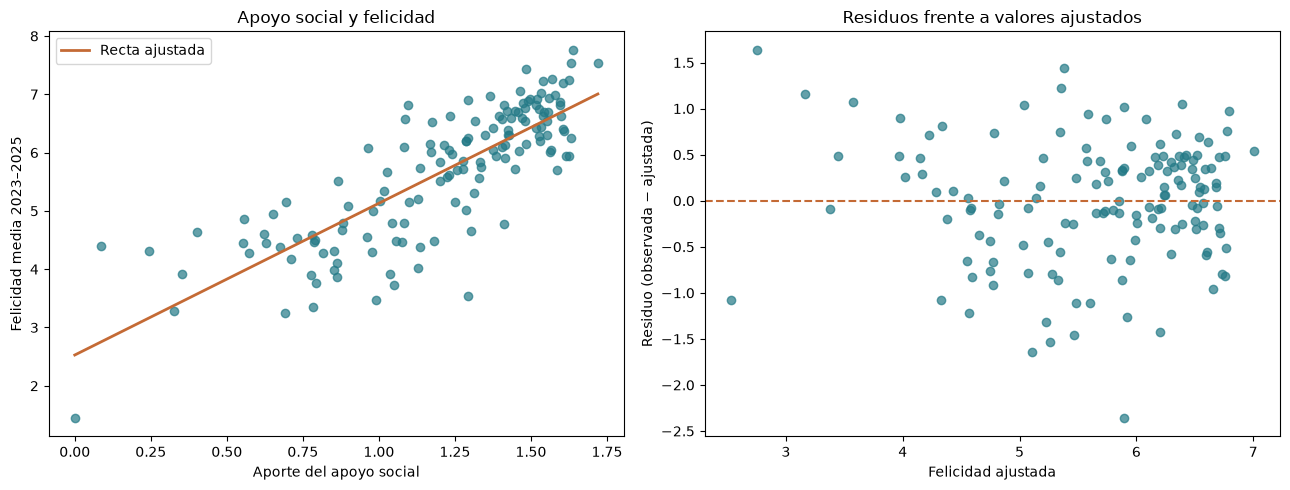

Países analizados: 145
Pendiente: 2.6032
Intercepto: 2.5278
R² del ajuste: 0.6591
RMSE del ajuste: 0.6652
Gráfico guardado: C:\Users\PC\Documents\Proyecto 6\reports\figures\regresion_apoyo_social.png
Resultados guardados: C:\Users\PC\Documents\Proyecto 6\reports\regresion_apoyo_social.csv


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Selecciono los países con ambos valores disponibles.
datos_regresion = df_factores[
    ["pais_original", "aporte_apoyo_social", "felicidad_media_3_anios"]
].dropna().copy()

x = datos_regresion["aporte_apoyo_social"].to_numpy()
y = datos_regresion["felicidad_media_3_anios"].to_numpy()

# Ajusto la recta mediante mínimos cuadrados.
pendiente, intercepto = np.polyfit(x, y, deg=1)
y_ajustada = intercepto + pendiente * x
residuos = y - y_ajustada

suma_residuos = np.sum(residuos ** 2)
suma_total = np.sum((y - y.mean()) ** 2)

r2 = 1 - suma_residuos / suma_total
rmse = np.sqrt(np.mean(residuos ** 2))

# Comparo los valores observados con la recta y reviso los residuos.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

orden = np.argsort(x)

axes[0].scatter(x, y, color="#247A87", alpha=0.7)
axes[0].plot(
    x[orden],
    y_ajustada[orden],
    color="#C46A35",
    linewidth=2,
    label="Recta ajustada",
)
axes[0].set(
    title="Apoyo social y felicidad",
    xlabel="Aporte del apoyo social",
    ylabel="Felicidad media 2023–2025",
)
axes[0].legend()

axes[1].scatter(y_ajustada, residuos, color="#247A87", alpha=0.7)
axes[1].axhline(0, color="#C46A35", linestyle="--")
axes[1].set(
    title="Residuos frente a valores ajustados",
    xlabel="Felicidad ajustada",
    ylabel="Residuo (observada − ajustada)",
)

fig.tight_layout()

ruta_figura = (
    carpeta_proyecto / "reports" / "figures" / "regresion_apoyo_social.png"
)
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_figura, dpi=150, bbox_inches="tight")
plt.show()

# Guardo los valores ajustados y los residuos para revisar el análisis.
datos_regresion["felicidad_ajustada"] = y_ajustada
datos_regresion["residuo"] = residuos

ruta_resultados = carpeta_proyecto / "reports" / "regresion_apoyo_social.csv"
datos_regresion.to_csv(
    ruta_resultados, index=False, encoding="utf-8-sig"
)

print(f"Países analizados: {len(datos_regresion)}")
print(f"Pendiente: {pendiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")
print(f"R² del ajuste: {r2:.4f}")
print(f"RMSE del ajuste: {rmse:.4f}")
print(f"Gráfico guardado: {ruta_figura}")
print(f"Resultados guardados: {ruta_resultados}")

### Interpretación de la regresión lineal

Obtengo la siguiente recta:

Felicidad ajustada = 2,5278 + 2,6032 × aporte del apoyo social.

Dentro del modelo, una diferencia de 0,1 puntos en el aporte del
apoyo social se asocia con una diferencia de aproximadamente
0,2603 puntos en la felicidad ajustada. Esta asociación no implica
que modificar el apoyo social cause ese cambio en la felicidad.

El R² es 0,6591: la recta recoge el 65,91 % de la variación observada
en felicidad entre los países analizados. Este porcentaje no representa
una proporción de felicidad causada por el apoyo social.

El RMSE es de 0,6652 puntos de felicidad y resume la magnitud de los
errores del ajuste, dando mayor peso a los errores grandes.
Ambas métricas se calculan sobre los mismos datos utilizados para
ajustar la recta; no miden su capacidad predictiva en datos nuevos.

El intercepto, 2,5278, es el valor que asigna la recta cuando el aporte
es cero. No lo interpreto como un nivel universal de felicidad
en ausencia de apoyo social.

### Revisión visual de los residuos

Observo residuos positivos y negativos alrededor de cero. Los positivos
corresponden a países cuya felicidad supera el valor ajustado; los
negativos, a países cuya felicidad queda por debajo.

La distribución no parece completamente aleatoria: en parte de la
zona intermedia predominan residuos negativos y en algunos valores
altos aparecen agrupaciones positivas. Esto sugiere que una recta
puede no recoger toda la estructura de la relación.

Destaca un residuo cercano a −2,4 puntos, correspondiente a un país
cuya felicidad es bastante inferior a la ajustada. Conservo este
registro: un error grande del modelo no demuestra un error en los datos.

Mantengo la regresión como resumen descriptivo de la asociación.
Este gráfico, por sí solo, no permite confirmar normalidad,
varianza constante ni independencia de los errores.